In [56]:
# Imports
import math
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
from scipy import stats
import seaborn as sns
import plotly.express as px

In [57]:
df_vitis = pd.read_csv('5x5Data/vitis_5x5_norag.csv')
df_vitis = df_vitis.sort_values(by=['model', 'run', 'kernel', 'attempt'])

model_names = {
    "gpt-4.1-mini": "GPT-4.1 mini",
    "grok-code-fast-1": "Grok Code Fast",
    "gemini-2.5-flash": "Gemini 2.5 Flash",
    "deepseek-chat-v3-0324": "Deepseek V3",
    "deepseek-r1-0528": "Deepseek R1",
    "qwen3-coder": "Qwen3 Coder",
    "grok-4": "Grok 4",
    "gemini-2.5-pro": "Gemini 2.5 Pro",
    "claude-sonnet-4.5": "Claude Sonnet 4.5",
    "gpt-5": "GPT 5"
}
df_vitis['model'] = df_vitis['model'].str.split('/').str[-1]

df_vitis['model'] = df_vitis['model'].map(model_names)
print(df_vitis)

                  model     RAG               kernel  run  attempt  \
480   Claude Sonnet 4.5  no_rag             abs_int8    1        1   
481   Claude Sonnet 4.5  no_rag             abs_int8    1        2   
482   Claude Sonnet 4.5  no_rag             abs_int8    1        3   
483   Claude Sonnet 4.5  no_rag             abs_int8    1        4   
484   Claude Sonnet 4.5  no_rag             abs_int8    1        5   
...                 ...     ...                  ...  ...      ...   
4750        Qwen3 Coder  no_rag  vectorsubtract_int8    5        1   
4751        Qwen3 Coder  no_rag  vectorsubtract_int8    5        2   
4752        Qwen3 Coder  no_rag  vectorsubtract_int8    5        3   
4753        Qwen3 Coder  no_rag  vectorsubtract_int8    5        4   
4754        Qwen3 Coder  no_rag  vectorsubtract_int8    5        5   

     compilation_status outputs_match  csim_success  fmax  latency  bram  dsp  \
480              passed         match          True   7.3   1041.0   3.0  0.0 

In [58]:
# Parse time columns (h:mm:s.ssss), compute stats, and plot/save figures
def time_to_seconds(t):
	"""Convert a time string like H:MM:SS.ssss or M:SS.ssss to seconds. Empty -> 0."""
	if pd.isna(t):
		return 0
	s = str(t).strip()
	if s == "":
		return 0
	try:
		parts = s.split(":")
		# seconds (may contain fractional part)
		secs = float(parts[-1])
		mins = int(parts[-2]) if len(parts) >= 2 and parts[-2] != '' else 0
		hours = int(parts[-3]) if len(parts) >= 3 and parts[-3] != '' else 0
		return hours * 3600 + mins * 60 + secs
	except Exception:
		return np.nan


# Apply conversions
for col in ['llm_time', 'csim_time', 'csynth_time']:
	if col in df_vitis.columns:
		df_vitis[f'{col}_s'] = df_vitis[col].apply(time_to_seconds)
	else:
		print(f'Warning: column {col} not found in df_vitis')


# Compute summary statistics per model
time_cols = [c for c in df_vitis.columns if c.endswith('_s')]
summary = df_vitis.groupby('model')[time_cols].agg(['count', 'mean', 'median', 'std']).reset_index()

print('\nTime summary (seconds) per model:')
print(summary.head(20))


# --- Plotting helpers ---
def save_fig(fig, name):
	path = f'{name}.pdf'
	fig.savefig(path, bbox_inches='tight')
	print(f'Saved {path}')




Time summary (seconds) per model:
               model llm_time_s                                  csim_time_s  \
                          count       mean     median        std       count   
0  Claude Sonnet 4.5       2525  13.395602  13.557747   5.235400        2525   
1   Gemini 2.5 Flash       2525   4.506762   4.002499   2.546161        2525   
2        Qwen3 Coder       2525   8.306431   5.338643  34.275040        2525   

                                  csynth_time_s                        \
        mean     median       std         count       mean     median   
0  19.381552  20.861458  2.744736          2525  25.122227  29.761016   
1  18.487763  20.689219  4.581169          2525  21.113340  21.297782   
2  18.451027  21.038971  4.967507          2525  20.556497  18.241699   

              
         std  
0   8.870366  
1  13.202607  
2  12.248841  


Wrote results/data_analysis/avg_time_per_model.csv
Wrote results/data_analysis/avg_time_by_model_attempt.csv
Wrote results/data_analysis/avg_cumulative_time_by_model_attempt.csv
Saved results/data_analysis/avg_cumulative_time_by_model_attempt.pdf


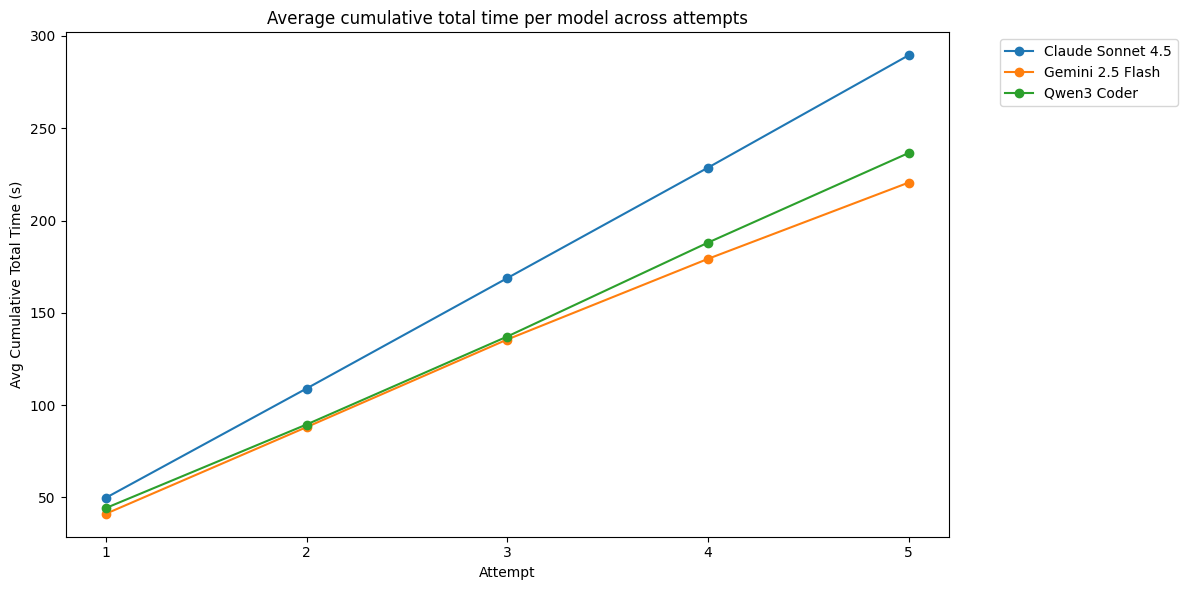

In [59]:
# Making the graph with the attempts separated and with dashed LInes and then the Cummulative on top
# Distinct colors for each trial using different colormaps
trial_colors = ['#4A90E2', '#50C878', '#9B59B6', '#E67E22', '#95A5A6']

# --- Additional: compute per-row total times and per-model/attempt averages ---
# Ensure the time-in-seconds columns exist (these were created earlier as *_s)
for _col in ['llm_time_s','csim_time_s','csynth_time_s']:
    if _col not in df_vitis.columns:
        df_vitis[_col] = np.nan

# Create total_time_s as sum of available components (treat missing as 0)
df_vitis['total_time_s'] = df_vitis[['llm_time_s','csim_time_s','csynth_time_s']].fillna(0).sum(axis=1)
# Flag rows where all three stages completed
df_vitis['completed_all_times'] = df_vitis[['llm_time_s','csim_time_s','csynth_time_s']].notna().all(axis=1)

# --- Cumulative total time across attempts per kernel/run ---
# Ensure df_vitis is ordered so cumulative sum is correct
if all(col in df_vitis.columns for col in ['model','run','kernel','attempt']):
    df_vitis = df_vitis.sort_values(by=['model','run','kernel','attempt'])
    df_vitis['cumulative_total_time_s'] = df_vitis.groupby(['model','run','kernel'])['total_time_s'].cumsum()
else:
    # fallback: compute cumsum grouped only by model/run/kernel if available
    df_vitis['cumulative_total_time_s'] = df_vitis.groupby(['model','run','kernel'])['total_time_s'].cumsum()

# Average time per model (overall)
avg_model_time = df_vitis.groupby('model')[['llm_time_s','csim_time_s','csynth_time_s','total_time_s','cumulative_total_time_s']].mean().reset_index()
avg_model_time = avg_model_time.rename(columns={
    'llm_time_s':'avg_llm_s',
    'csim_time_s':'avg_csim_s',
    'csynth_time_s':'avg_csynth_s',
    'total_time_s':'avg_total_s',
    'cumulative_total_time_s':'avg_cumulative_total_s'
})
# avg_model_time.to_csv('avg_time_per_model.csv', index=False)
print('Wrote results/data_analysis/avg_time_per_model.csv')

# Average time per model for each attempt (1..5)
if 'attempt' in df_vitis.columns:
    avg_by_model_attempt = df_vitis.groupby(['model','attempt'])[['llm_time_s','csim_time_s','csynth_time_s','total_time_s','cumulative_total_time_s']].mean().reset_index()
    # avg_by_model_attempt.to_csv('avg_time_by_model_attempt.csv', index=False)
    print('Wrote results/data_analysis/avg_time_by_model_attempt.csv')

    # Also save average cumulative time per model/attempt
    avg_cum_by_model_attempt = avg_by_model_attempt[['model','attempt','cumulative_total_time_s']].rename(columns={'cumulative_total_time_s':'avg_cum_total_s'})
    # avg_cum_by_model_attempt.to_csv('avg_cumulative_time_by_model_attempt.csv', index=False)
    print('Wrote results/data_analysis/avg_cumulative_time_by_model_attempt.csv')

    # Pivot cumulative total for plotting attempts (rows=attempt, cols=models)
    pivot_cum = avg_cum_by_model_attempt.pivot(index='attempt', columns='model', values='avg_cum_total_s')
    fig, ax = plt.subplots(figsize=(12,6))
    for model in pivot_cum.columns:
        ax.plot(pivot_cum.index, pivot_cum[model], marker='o', label=model)
    ax.set_xlabel('Attempt')
    ax.set_ylabel('Avg Cumulative Total Time (s)')
    ax.set_title('Average cumulative total time per model across attempts')
    ax.legend(bbox_to_anchor=(1.05,1), loc='upper left')
    # Ensure attempts appear in order
    try:
        ax.set_xticks(sorted(df_vitis['attempt'].dropna().unique()))
    except Exception:
        pass
    plt.tight_layout()
    # fig.savefig('avg_cumulative_time_by_model_attempt.pdf', bbox_inches='tight')
    print('Saved results/data_analysis/avg_cumulative_time_by_model_attempt.pdf')
    plt.show()
else:
    print('Column "attempt" not found in df_vitis; skipping per-attempt aggregation/plot')

Saved results/data_analysis/cumulative_time_breakdown_by_attempt.pdf


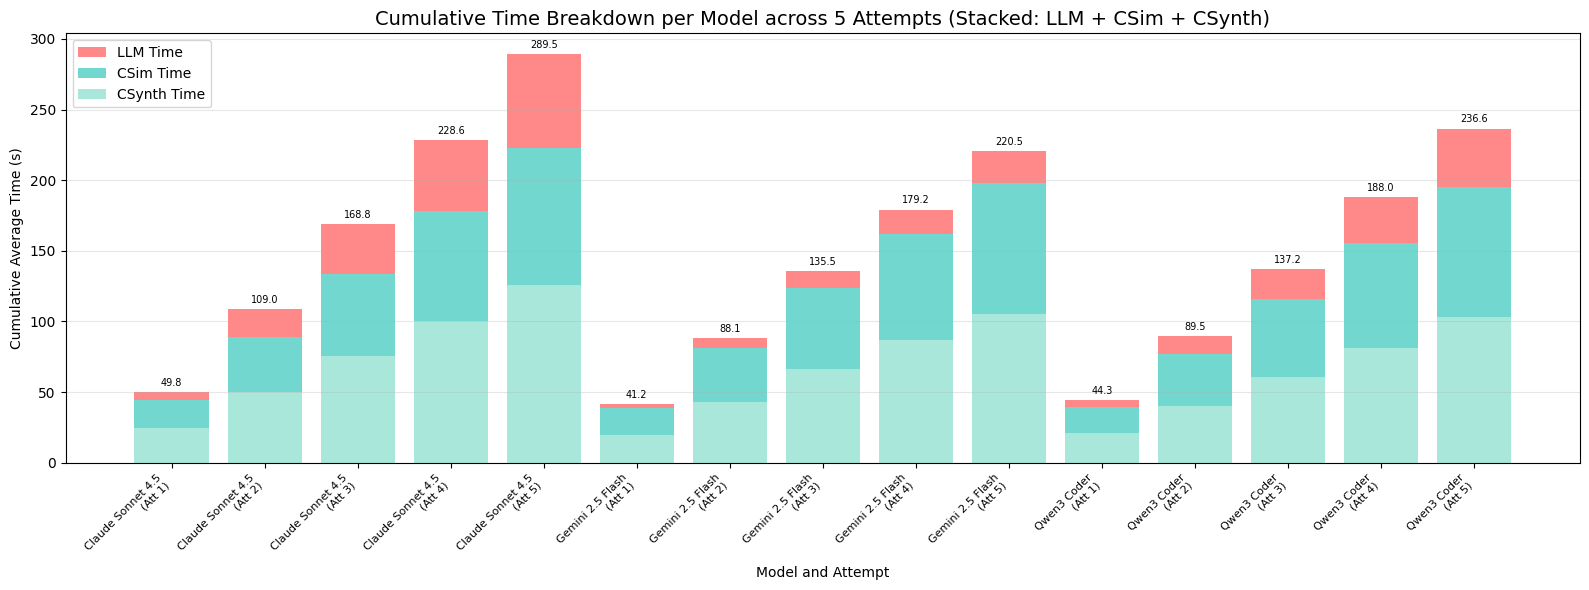

In [60]:

# --- CUMULATIVE TIME BREAKDOWN: stacked bars showing cumulative totals across attempts ---
# Compute average time components per model & attempt
models_for_plot = df_vitis['model'].unique()

# Ensure time component columns exist
for col in ['llm_time_s','csim_time_s','csynth_time_s']:
    if col not in df_vitis.columns:
        df_vitis[col] = np.nan

# Group by model and attempt, compute means
avg_time_breakdown = df_vitis.groupby(['model','attempt'])[['llm_time_s','csim_time_s','csynth_time_s']].mean().reset_index()
avg_time_breakdown = avg_time_breakdown[avg_time_breakdown['model'].isin(models_for_plot)]
avg_time_breakdown['attempt'] = avg_time_breakdown['attempt'].astype(int)
avg_time_breakdown = avg_time_breakdown.sort_values(['model','attempt'])

# Prepare models and attempts
models = list(dict.fromkeys(models_for_plot))
attempts = sorted(avg_time_breakdown['attempt'].unique())

# Compute cumulative sums for each model
cumulative_data = []
for m in models:
    model_data = avg_time_breakdown[avg_time_breakdown['model']==m].sort_values('attempt')
    if not model_data.empty:
        llm_cumsum = model_data['llm_time_s'].fillna(0).cumsum()
        csim_cumsum = model_data['csim_time_s'].fillna(0).cumsum()
        csynth_cumsum = model_data['csynth_time_s'].fillna(0).cumsum()
        
        for idx, (att, llm_c, csim_c, csynth_c) in enumerate(zip(model_data['attempt'], llm_cumsum, csim_cumsum, csynth_cumsum)):
            cumulative_data.append({
                'model': m,
                'attempt': att,
                'llm_cumsum': llm_c,
                'csim_cumsum': csim_c,
                'csynth_cumsum': csynth_c
            })

cum_df = pd.DataFrame(cumulative_data)

# Prepare grouped bar positions (one bar per model/attempt)
x_pos = 0
bar_positions = {}
bar_labels = []
llm_vals = []
csim_vals = []
csynth_vals = []

for m in models:
    for a in attempts:
        row = cum_df[(cum_df['model']==m) & (cum_df['attempt']==a)]
        if not row.empty:
            bar_positions[f"{m}_a{a}"] = x_pos
            bar_labels.append(f"{m}\n(Att {a})")
            llm_vals.append(float(row['llm_cumsum'].values[0]))
            csim_vals.append(float(row['csim_cumsum'].values[0]))
            csynth_vals.append(float(row['csynth_cumsum'].values[0]))
            x_pos += 1

x_positions = np.arange(len(llm_vals))

fig, ax = plt.subplots(figsize=(16,6))

# Colors for each time component
colors_cumul = {'llm': '#FF6B6B', 'csim': '#4ECDC4', 'csynth': '#95E1D3'}

# Stack the bars: llm (bottom), csim (middle), csynth (top)
ax.bar(x_positions, llm_vals, bottom=np.array(csim_vals)+np.array(csynth_vals), label='LLM Time', color=colors_cumul['llm'], alpha=0.8)
ax.bar(x_positions, csim_vals, bottom=np.array(csynth_vals), label='CSim Time', color=colors_cumul['csim'], alpha=0.8)
ax.bar(x_positions, csynth_vals, label='CSynth Time', color=colors_cumul['csynth'], alpha=0.8)

# Annotate total on top of each bar
totals = np.array(llm_vals) + np.array(csim_vals) + np.array(csynth_vals)
for xi, total in zip(x_positions, totals):
    ax.annotate(f"{total:.1f}", (xi, total), ha='center', va='bottom', xytext=(0,3), textcoords='offset points', fontsize=7)

ax.set_xlabel('Model and Attempt')
ax.set_ylabel('Cumulative Average Time (s)')
ax.set_title('Cumulative Time Breakdown per Model across 5 Attempts (Stacked: LLM + CSim + CSynth)', fontsize=14)
ax.set_xticks(x_positions)
ax.set_xticklabels(bar_labels, fontsize=8, rotation=45, ha='right')
ax.legend(loc='upper left', fontsize=10)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()

# Save PDF to results folder
out_path = 'results/data_analysis/cumulative_time_breakdown_by_attempt.pdf'
import os
os.makedirs('results/data_analysis', exist_ok=True)
plt.savefig(out_path, bbox_inches='tight')
print(f'Saved {out_path}')
plt.show()

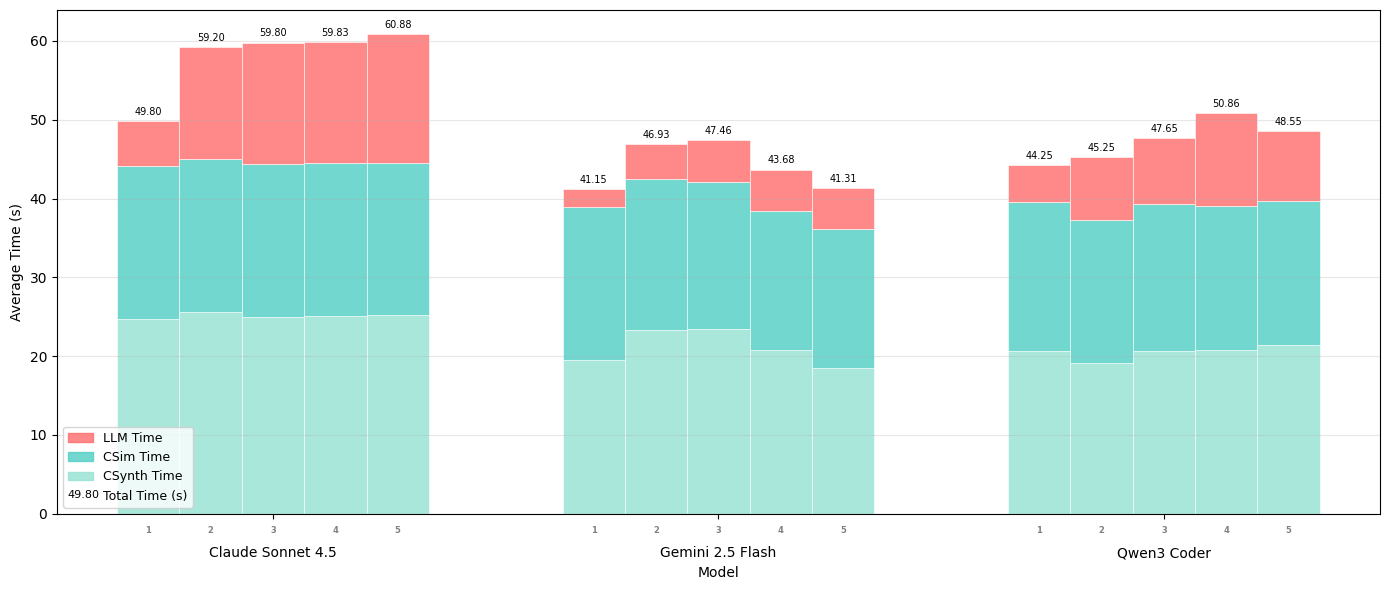

In [61]:

# --- NEW: Non-cumulative time barplot with breakdown (stacked: llm + csim + csynth) ---
# Compute average time components per model & attempt
models_for_plot = df_vitis['model'].unique()

# Ensure time component columns exist
for col in ['llm_time_s','csim_time_s','csynth_time_s']:
    if col not in df_vitis.columns:
        df_vitis[col] = np.nan

# Group by model and attempt, compute means
avg_time_breakdown = df_vitis.groupby(['model','attempt'])[['llm_time_s','csim_time_s','csynth_time_s']].mean().reset_index()
avg_time_breakdown = avg_time_breakdown[avg_time_breakdown['model'].isin(models_for_plot)]
avg_time_breakdown['attempt'] = avg_time_breakdown['attempt'].astype(int)

# Prepare models and attempts
models = list(dict.fromkeys(models_for_plot))
attempts = sorted(avg_time_breakdown['attempt'].unique())

# Prepare grouped bar positions
n_models = len(models)
n_attempts = len(attempts)
width = 0.7 / max(1, n_attempts)
x = np.arange(n_models)

fig, ax = plt.subplots(figsize=(14,6))

# Colors for each time component
colors = {'llm_time_s': '#FF6B6B', 'csim_time_s': '#4ECDC4', 'csynth_time_s': '#95E1D3'}
component_names = {'llm_time_s': 'LLM Time', 'csim_time_s': 'CSim Time', 'csynth_time_s': 'CSynth Time'}

cumulative_llm = 0
cumulative_csim = 0
cumulative_csynth = 0
for i, a in enumerate(attempts):
    llm_means = []
    csim_means = []
    csynth_means = []
    
    for m in models:
        row = avg_time_breakdown[(avg_time_breakdown['model']==m) & (avg_time_breakdown['attempt']==a)]
        if not row.empty:
            llm_means.append(float(row['llm_time_s'].values[0]) if not np.isnan(row['llm_time_s'].values[0]) else 0)
            csim_means.append(float(row['csim_time_s'].values[0]) if not np.isnan(row['csim_time_s'].values[0]) else 0)
            csynth_means.append(float(row['csynth_time_s'].values[0]) if not np.isnan(row['csynth_time_s'].values[0]) else 0)
        else:
            llm_means.append(0)
            csim_means.append(0)
            csynth_means.append(0)
    
    llm_arr = np.array(llm_means)
    csim_arr = np.array(csim_means)
    csynth_arr = np.array(csynth_means)
    # print(llm_arr)
    # print(csim_arr)
    # print(csynth_arr)
    # Center each model's group of bars on the x tick: compute total group width
    total_width = width * n_attempts
    positions = x - total_width / 2 + i*width + width/2
    
    # Stack the bars: llm (bottom), csim (middle), csynth (top)
    # ax.bar(positions, llm_arr, width=width, label=f'LLM (Attempt {a})' if i == 0 else '', color=colors['llm_time_s'], alpha=0.8)
    # ax.bar(positions, csim_arr, width=width, bottom=llm_arr, label=f'CSim (Attempt {a})' if i == 0 else '', color=colors['csim_time_s'], alpha=0.8)
    # ax.bar(positions, csynth_arr, width=width, bottom=llm_arr+csim_arr, label=f'CSynth (Attempt {a})' if i == 0 else '', color=colors['csynth_time_s'], alpha=0.8)
    ax.bar(positions, csynth_arr, width=width, label=f'CSynth (Attempt {a})' if i == 0 else '', color=colors['csynth_time_s'], alpha=0.8, edgecolor='white', linewidth=0.5)
    ax.bar(positions, csim_arr, width=width, bottom=csynth_arr, label=f'CSim (Attempt {a})' if i == 0 else '', color=colors['csim_time_s'], alpha=0.8, edgecolor='white', linewidth=0.5)
    ax.bar(positions, llm_arr, width=width, bottom=csynth_arr+csim_arr ,label=f'LLM (Attempt {a})' if i == 0 else '', color=colors['llm_time_s'], alpha=0.8, edgecolor='white', linewidth=0.5)

    for xi in positions:    
        # We place the label slightly below the 0 line
        ax.text(xi, -1.5, str(a), ha='center', va='top', fontsize=6, color='gray', fontweight='bold')

    # Update cumulative sums (for each model across attempts)
    cumulative_llm += llm_arr
    cumulative_csim += csim_arr
    cumulative_csynth += csynth_arr

    # Annotate cumulative totals on top of each bar
    normal_totals = llm_arr + csim_arr + csynth_arr
    cumulative_totals = cumulative_llm + cumulative_csim + cumulative_csynth
    # print(cumulative_totals)
    for xi, total, total_norm in zip(positions, cumulative_totals, normal_totals):
        # print(xi)
        # print(total)
        # print(total_norm)
        if total > 0:
            ax.annotate(f"{total_norm:.2f}", (xi, total_norm), ha='center', va='bottom', xytext=(0,3), textcoords='offset points', fontsize=7)

ax.set_xlabel('Model')
ax.set_ylabel('Average Time (s)')
# ax.set_title('Average Time Breakdown per Run over 5 Attempts (Stacked: LLM + CSim + CSynth)', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(models, ha='center')
ax.tick_params(axis='x', which='major', pad=20)
ax.grid(axis='y', alpha=0.3)

# Create a custom label that includes the example time
example_time = 49.80
time_text = f'{example_time:.2f}'
explanation_text = 's Cumulative Time'

# Custom legend: one entry per component + attempts + annotation explanation
handles = [plt.Rectangle((0,0),1,1, color=colors['llm_time_s'], alpha=0.8),
           plt.Rectangle((0,0),1,1, color=colors['csim_time_s'], alpha=0.8),
           plt.Rectangle((0,0),1,1, color=colors['csynth_time_s'], alpha=0.8)]
labels = ['LLM Time', 'CSim Time', 'CSynth Time']
attempt_handles = [plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='gray', markersize=8, label=f'Attempt {a}') for a in attempts]
# Invisible/text-only handle for explanatory legend entry
empty_handle = [plt.Line2D([],[], linestyle='')]
legend_handles = handles + empty_handle
legend_labels = labels + ['Total Time (s)']
main_legend = ax.legend(legend_handles, legend_labels, loc='lower left', fontsize=9)
# Get the coordinates of the legend box in display space
renderer = ax.figure.canvas.get_renderer()
legend_bbox = main_legend.get_window_extent(renderer=renderer)

# Convert the bounding box coordinates back to axes coordinates (0 to 1)
ax_coords_legend = ax.transAxes.inverted().transform(legend_bbox)

# Compute a point inside the legend box (top-left inside the box) and overlay text on top
x_left = ax_coords_legend[0, 0]
y_bottom = ax_coords_legend[0, 1] + 0.053
x_right = ax_coords_legend[1, 0]
y_top = ax_coords_legend[1, 1]
pad_x = 0.002
pad_y = 0.02
x_text_inside = x_left + pad_x
y_text_inside = y_bottom - pad_y
# Place the number inside/over the legend box, with higher zorder so it appears in front
ax.text(
    x_text_inside,
    y_text_inside,
    s=f'{time_text}',
    transform=ax.transAxes,
    fontsize=8,
    ha='left',
    va='top',
    zorder=1000,
    color='black'
)

plt.tight_layout()
plt.savefig("time_analysis.pdf", dpi=300, bbox_inches='tight')   




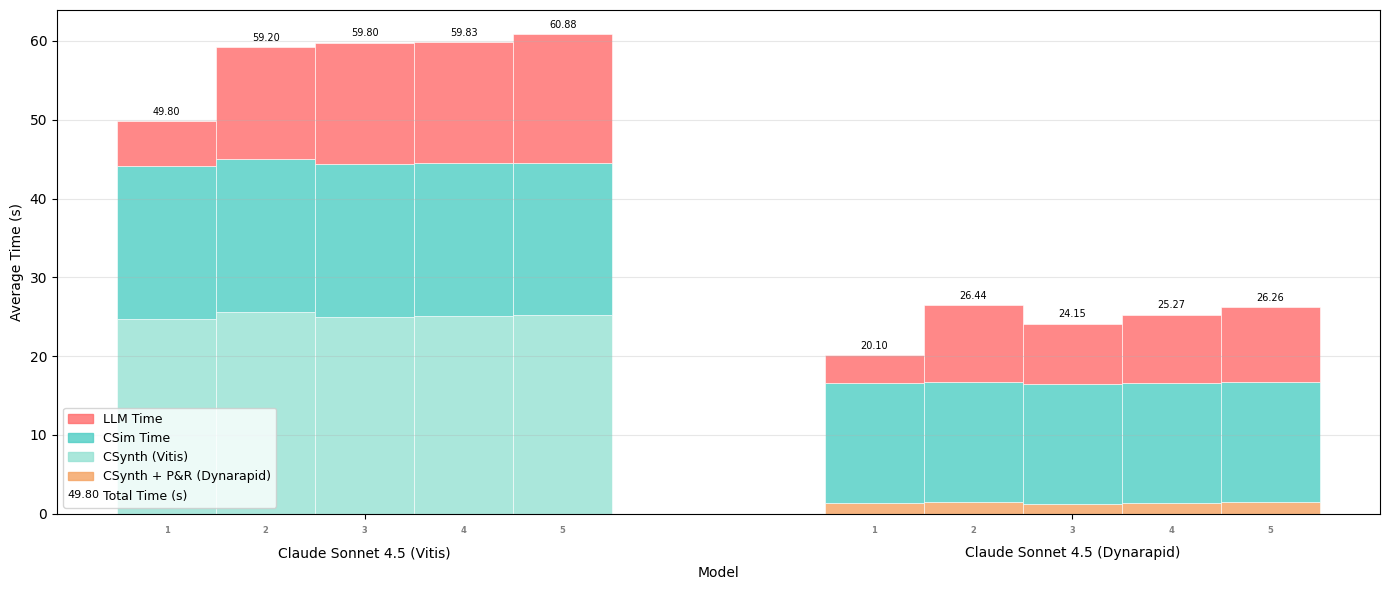

In [62]:
# --- NEW: Non-cumulative time barplot with breakdown (stacked: llm + csim + csynth) ---
# Compute average time components per model & attempt
models_for_plot = df_vitis['model'].unique()

# Ensure time component columns exist
for col in ['llm_time_s','csim_time_s','csynth_time_s']:
    if col not in df_vitis.columns:
        df_vitis[col] = np.nan

# Group by model and attempt, compute means
avg_time_breakdown = df_vitis.groupby(['model','attempt'])[['llm_time_s','csim_time_s','csynth_time_s']].mean().reset_index()
avg_time_breakdown = avg_time_breakdown[avg_time_breakdown['model'].isin(models_for_plot)]
avg_time_breakdown['attempt'] = avg_time_breakdown['attempt'].astype(int)

# Option: compare Claude (Vitis) with Dynarapid Claude
import os
compare_claude_dynarapid = True
if compare_claude_dynarapid:
    dyna_path = '5x5Data/dynarapid_5x5_norag.csv'
    if os.path.exists(dyna_path):
        df_dyna = pd.read_csv(dyna_path)
        # Normalize model names similarly to df_vitis
        df_dyna['model'] = df_dyna['model'].str.split('/').str[-1]
        if 'model_names' in globals():
            df_dyna['model'] = df_dyna['model'].map(model_names).fillna(df_dyna['model'])
        # Convert dynarapid time columns to seconds
        for col in ['llm_time','sim_time','dynarapid_time']:
            if col in df_dyna.columns:
                df_dyna[f'{col}_s'] = df_dyna[col].apply(time_to_seconds)
            else:
                df_dyna[f'{col}_s'] = 0
        # Filter to Claude models only
        df_vitis_claude = df_vitis[df_vitis['model'].str.contains('Claude', na=False)].copy()
        df_dyna_claude = df_dyna[df_dyna['model'].str.contains('Claude', na=False)].copy()
        if not df_vitis_claude.empty and not df_dyna_claude.empty:
            # Tag sources so they appear as separate "models" on the plot
            df_vitis_claude['model'] = df_vitis_claude['model'] + ' (Vitis)'
            df_dyna_claude['model'] = df_dyna_claude['model'] + ' (Dynarapid)'
            # Align dynarapid column names with vitis ones
            df_dyna_claude = df_dyna_claude.rename(columns={'sim_time_s':'csim_time_s','dynarapid_time_s':'csynth_time_s'})
            # Combine and recompute averages so the rest of the plotting code can be reused
            combo = pd.concat([
                df_vitis_claude[['model','attempt','llm_time_s','csim_time_s','csynth_time_s']],
                df_dyna_claude[['model','attempt','llm_time_s','csim_time_s','csynth_time_s']]
            ], ignore_index=True)
            avg_time_breakdown = combo.groupby(['model','attempt'])[['llm_time_s','csim_time_s','csynth_time_s']].mean().reset_index()
            models_for_plot = avg_time_breakdown['model'].unique()
        else:
            print('Warning: Claude data missing in one of the datasets; falling back to Vitis-only plot')

# Prepare models and attempts
models = list(dict.fromkeys(models_for_plot))
# Reorder models so Vitis entries come first, then Dynarapid, then others
def _order_fn(m):
    if 'Vitis' in m:
        return (0, m)
    if 'Dynarapid' in m:
        return (1, m)
    return (2, m)
models = sorted(models, key=_order_fn)

attempts = sorted(avg_time_breakdown['attempt'].unique())

# Prepare grouped bar positions
n_models = len(models)
n_attempts = len(attempts)
width = 0.7 / max(1, n_attempts)
x = np.arange(n_models)

fig, ax = plt.subplots(figsize=(14,6))

# Colors for each time component
colors = {'llm_time_s': '#FF6B6B', 'csim_time_s': '#4ECDC4', 'csynth_time_s': '#95E1D3'}
# Distinct color for Dynarapid's CSynth+Implementation (so it differs from Vitis CSynth)
dyn_csynth_color = '#F4A261'
component_names = {'llm_time_s': 'LLM Time', 'csim_time_s': 'CSim Time', 'csynth_time_s': 'CSynth Time', 'dyn_csynth_time_s': 'CSynth + P&R (Dynarapid)'}

cumulative_llm = 0
cumulative_csim = 0
cumulative_csynth = 0
for i, a in enumerate(attempts):
    llm_means = []
    csim_means = []
    csynth_means = []
    
    for m in models:
        row = avg_time_breakdown[(avg_time_breakdown['model']==m) & (avg_time_breakdown['attempt']==a)]
        if not row.empty:
            llm_means.append(float(row['llm_time_s'].values[0]) if not np.isnan(row['llm_time_s'].values[0]) else 0)
            csim_means.append(float(row['csim_time_s'].values[0]) if not np.isnan(row['csim_time_s'].values[0]) else 0)
            csynth_means.append(float(row['csynth_time_s'].values[0]) if not np.isnan(row['csynth_time_s'].values[0]) else 0)
        else:
            llm_means.append(0)
            csim_means.append(0)
            csynth_means.append(0)
    
    llm_arr = np.array(llm_means)
    csim_arr = np.array(csim_means)
    csynth_arr = np.array(csynth_means)
    # print(llm_arr)
    # print(csim_arr)
    # print(csynth_arr)
    # Center each model's group of bars on the x tick: compute total group width
    total_width = width * n_attempts
    positions = x - total_width / 2 + i*width + width/2
    
    # Stack the bars: llm (bottom), csim (middle), csynth (top)
    # ax.bar(positions, llm_arr, width=width, label=f'LLM (Attempt {a})' if i == 0 else '', color=colors['llm_time_s'], alpha=0.8)
    # ax.bar(positions, csim_arr, width=width, bottom=llm_arr, label=f'CSim (Attempt {a})' if i == 0 else '', color=colors['csim_time_s'], alpha=0.8)
    # Use per-model colors for CSynth so Dynarapid CSynth+P&R appears distinct from Vitis CSynth
    csynth_colors = [dyn_csynth_color if 'Dynarapid' in m else colors['csynth_time_s'] for m in models]
    ax.bar(positions, csynth_arr, width=width, label=f'CSynth (Attempt {a})' if i == 0 else '', color=csynth_colors, alpha=0.8, edgecolor='white', linewidth=0.5)
    ax.bar(positions, csim_arr, width=width, bottom=csynth_arr, label=f'CSim (Attempt {a})' if i == 0 else '', color=colors['csim_time_s'], alpha=0.8, edgecolor='white', linewidth=0.5)
    ax.bar(positions, llm_arr, width=width, bottom=csynth_arr+csim_arr ,label=f'LLM (Attempt {a})' if i == 0 else '', color=colors['llm_time_s'], alpha=0.8, edgecolor='white', linewidth=0.5)

    for xi in positions:    
        # We place the label slightly below the 0 line
        ax.text(xi, -1.5, str(a), ha='center', va='top', fontsize=6, color='gray', fontweight='bold')

    # Update cumulative sums (for each model across attempts)
    cumulative_llm += llm_arr
    cumulative_csim += csim_arr
    cumulative_csynth += csynth_arr

    # Annotate cumulative totals on top of each bar
    normal_totals = llm_arr + csim_arr + csynth_arr
    cumulative_totals = cumulative_llm + cumulative_csim + cumulative_csynth
    # print(cumulative_totals)
    for xi, total, total_norm in zip(positions, cumulative_totals, normal_totals):
        # print(xi)
        # print(total)
        # print(total_norm)
        if total > 0:
            ax.annotate(f"{total_norm:.2f}", (xi, total_norm), ha='center', va='bottom', xytext=(0,3), textcoords='offset points', fontsize=7)

ax.set_xlabel('Model')
ax.set_ylabel('Average Time (s)')
# ax.set_title('Average Time Breakdown per Run over 5 Attempts (Stacked: LLM + CSim + CSynth)', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(models, ha='center')
ax.tick_params(axis='x', which='major', pad=20)
ax.grid(axis='y', alpha=0.3)

# Create a custom label that includes the example time
example_time = 49.80
time_text = f'{example_time:.2f}'
explanation_text = 's Cumulative Time'

# Custom legend: one entry per component + attempts + annotation explanation
handles = [plt.Rectangle((0,0),1,1, color=colors['llm_time_s'], alpha=0.8),
           plt.Rectangle((0,0),1,1, color=colors['csim_time_s'], alpha=0.8)]
labels = ['LLM Time', 'CSim Time']
# Add CSynth (Vitis) handle; add Dynarapid CSynth+P&R handle if present
handles.append(plt.Rectangle((0,0),1,1, color=colors['csynth_time_s'], alpha=0.8))
labels.append('CSynth (Vitis)')
if any('Dynarapid' in m for m in models):
    handles.append(plt.Rectangle((0,0),1,1, color=dyn_csynth_color, alpha=0.8))
    labels.append('CSynth + P&R (Dynarapid)')

attempt_handles = [plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='gray', markersize=8, label=f'Attempt {a}') for a in attempts]
# Invisible/text-only handle for explanatory legend entry
empty_handle = [plt.Line2D([],[], linestyle='')]
legend_handles = handles + empty_handle
legend_labels = labels + ['Total Time (s)']
main_legend = ax.legend(legend_handles, legend_labels, loc='lower left', fontsize=9)
# Get the coordinates of the legend box in display space
renderer = ax.figure.canvas.get_renderer()
legend_bbox = main_legend.get_window_extent(renderer=renderer)

# Convert the bounding box coordinates back to axes coordinates (0 to 1)
ax_coords_legend = ax.transAxes.inverted().transform(legend_bbox)

# Compute a point inside the legend box (top-left inside the box) and overlay text on top
x_left = ax_coords_legend[0, 0]
y_bottom = ax_coords_legend[0, 1] + 0.053
x_right = ax_coords_legend[1, 0]
y_top = ax_coords_legend[1, 1]
pad_x = 0.002
pad_y = 0.02
x_text_inside = x_left + pad_x
y_text_inside = y_bottom - pad_y
# Place the number inside/over the legend box, with higher zorder so it appears in front
ax.text(
    x_text_inside,
    y_text_inside,
    s=f'{time_text}',
    transform=ax.transAxes,
    fontsize=8,
    ha='left',
    va='top',
    zorder=1000,
    color='black'
)

plt.tight_layout()
plt.savefig("time_analysis_dynarapid.pdf", dpi=300, bbox_inches='tight')